# Ensemble Learning Assignment: Forecasting Pettah Wholesale Beans Prices

**Prakasan R. (224152U)**

**Problem:** predict next week's average wholesale price of beans at Pettah market, so farmers, traders and small eateries can plan when to buy and sell.

**Data:** Central Bank of Sri Lanka, Daily Price Report, via Macro Lab (macrolab.lk), Aug 2016 to Nov 2026.


## Step 1: Load and understand the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/daily-prices-d.csv", comment="#", parse_dates=["period"])
df.shape

(2470, 263)

In [2]:
cols = {
    "Beans (wholesale, pettah) (Rs/kg)":   "beans_pettah",
    "Beans (wholesale, dambulla) (Rs/kg)": "beans_dambulla",
    "Carrot (wholesale, pettah) (Rs/kg)":  "carrot_pettah",
    "Cabbage (wholesale, pettah) (Rs/kg)": "cabbage_pettah",
}

data = df[["period"] + list(cols)].rename(columns=cols)
data = data.rename(columns={"period": "date"}).set_index("date").sort_index()
data.head()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
date,,,,
2016-08-01,140.0,130.0,100.0,80.0
2016-08-02,140.0,145.0,100.0,80.0
2016-08-03,120.0,155.0,100.0,70.0
2016-08-04,105.0,150.0,100.0,60.0
2016-08-05,105.0,150.0,100.0,60.0


In [3]:
print(data.isna().sum())
data.describe().round(1)

beans_pettah      79
beans_dambulla    62
carrot_pettah     80
cabbage_pettah    80
dtype: int64


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
count,2391.0,2408.0,2390.0,2390.0
mean,272.4,243.8,212.6,136.0
std,167.8,146.6,166.0,105.7
min,30.0,30.0,35.0,15.0
25%,140.0,125.0,100.0,65.0
50%,220.0,205.0,163.0,100.0
75%,400.0,325.0,280.0,180.0
max,1200.0,1100.0,2000.0,700.0


In [4]:
weekly = data.resample("W-FRI").mean()
weekly = weekly.iloc[:-1]      # drop the current week, which isn't finished yet
print(weekly.shape)
print(weekly.isna().sum())

(537, 4)
beans_pettah      10
beans_dambulla     3
carrot_pettah     10
cabbage_pettah    10
dtype: int64


In [5]:
weekly[weekly["beans_pettah"].isna()].index


DatetimeIndex(['2020-04-17', '2020-04-24', '2020-10-30', '2020-11-06',
               '2020-11-13', '2020-11-20', '2020-11-27', '2020-12-04',
               '2020-12-11', '2026-04-17'],
              dtype='datetime64[ns]', name='date', freq=None)

In [6]:
weekly["was_missing"] = weekly["beans_pettah"].isna().astype(int)
weekly = weekly.interpolate(method="time")
weekly.isna().sum()



beans_pettah      0
beans_dambulla    0
carrot_pettah     0
cabbage_pettah    0
was_missing       0
dtype: int64

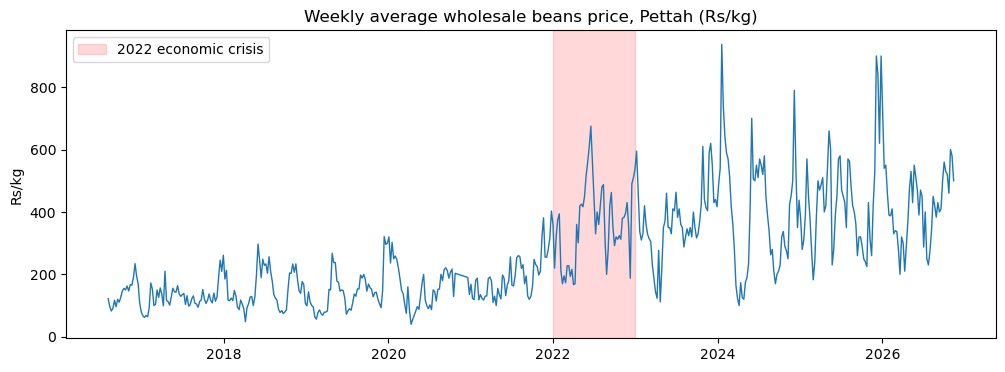

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(weekly.index, weekly["beans_pettah"], linewidth=1)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"),
           alpha=0.15, color="red", label="2022 economic crisis")
ax.set_title("Weekly average wholesale beans price, Pettah (Rs/kg)")
ax.set_ylabel("Rs/kg")
ax.legend()
plt.show()

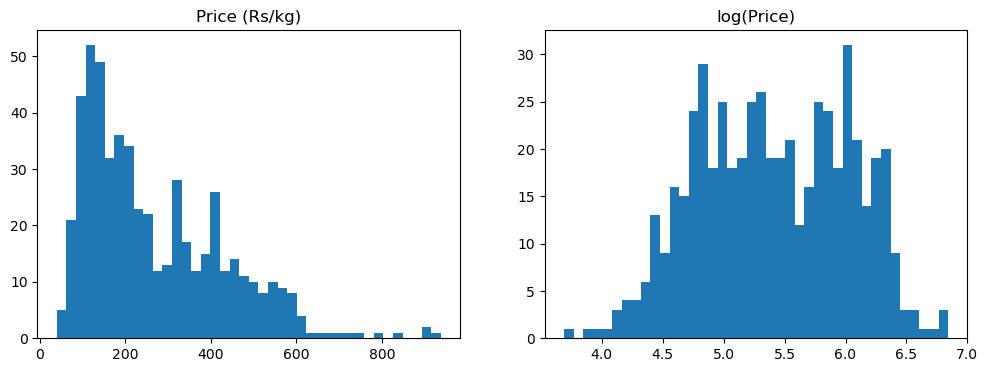

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(weekly["beans_pettah"], bins=40)
axes[0].set_title("Price (Rs/kg)")
axes[1].hist(np.log(weekly["beans_pettah"]), bins=40)
axes[1].set_title("log(Price)")
plt.show()

In [9]:
weekly.to_csv("dataset/weekly_clean.csv")
weekly.tail()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing
date,,,,,
2026-10-16,520.0,375.0,218.0,420.0,0
2026-10-23,460.0,392.0,206.0,410.0,0
2026-10-30,600.0,459.0,340.0,490.0,0
2026-11-06,580.0,498.0,440.0,600.0,0
2026-11-13,500.0,409.0,540.0,620.0,0
